In [9]:
# Import libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

In [10]:
# Load dataset
df=pd.read_csv("DecisionTree_RandomForest_Dataset.csv")
# print(db)

# Show dataset
print("First 5 rows:\n", df.head())

First 5 rows:
         Age    Income  Experience  Credit_Score  Transaction_Count  \
0  0.243847 -0.164471   -0.705182     -0.015433          -0.078425   
1  0.650237  0.274936   -0.776536     -0.959132          -1.123291   
2 -3.390672 -0.590640   -1.343470      6.169133           1.222753   
3  0.064793 -0.032960   -0.723131     -1.063065          -0.201072   
4  0.438060 -0.914989    0.953398     -0.033631          -0.048063   

   Activity_Level  Login_Time  Risk_Level  Target  
0        0.730461    0.363777    0.727296       0  
1       -0.572504   -0.918580    0.073886       0  
2        1.439649   -1.715076    3.223089       1  
3       -0.770711    0.890636   -1.379626       1  
4       -0.860909    0.511169   -0.449294       0  


In [11]:

# Separate features and target
# Assume last column is target (change if needed)
X = df.iloc[:, :-1]
y = df.iloc[:, -1]


# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


print("X_train",'\n',X_train)
print('\n',"X_test",'\n',X_test)
print('\n',"y_train",'\n',y_train)
print('\n',"y_test",'\n',y_test)


X_train 
           Age    Income  Experience  Credit_Score  Transaction_Count  \
29   1.128035 -1.211511   -0.346710      0.040964           0.773143   
535  0.836576  0.461283   -2.424151     -2.006380           0.969281   
695  1.350408  1.564162   -1.443557     -4.254685          -1.173838   
557 -0.171106  0.009920   -0.382593      0.056236          -0.156816   
836 -1.861524 -0.588641    0.204668      1.867301          -0.476138   
..        ...       ...         ...           ...                ...   
106  3.670452 -0.388081    2.437243     -4.139829           0.441974   
270 -0.962450 -0.451397   -0.714496      3.252310          -0.631704   
860  4.605669  0.467788   -0.337057     -5.162454           0.514971   
435 -1.697602 -1.580937   -0.648300      2.864573          -0.999749   
102 -1.062456 -1.839272   -1.250074      1.474421          -0.671981   

     Activity_Level  Login_Time  Risk_Level  
29         1.185066    1.659984    0.971991  
535        1.493251    2.329397  


--- Decision Tree ---
Accuracy: 0.92
Confusion Matrix:
 [[85 10]
 [ 6 99]]


/opt/conda/envs/anaconda-2025.12-py312/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 127795 (\N{DECIDUOUS TREE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


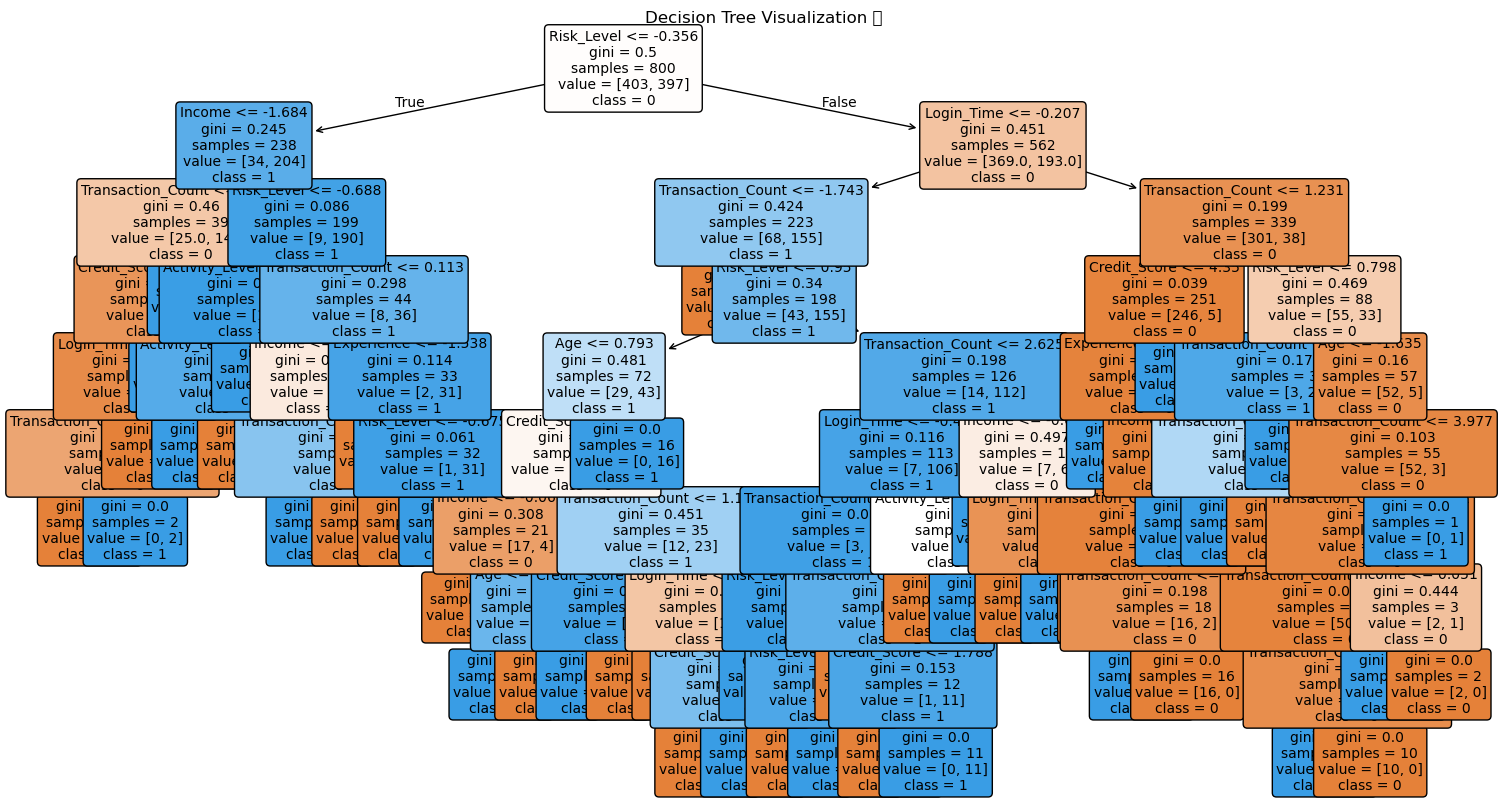

In [28]:
# Decision Tree Model

dt = DecisionTreeClassifier()
dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)

print("\n--- Decision Tree ---")
print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_dt))


# plot
# Get one tree from Random Forest
plt.figure(figsize=(18,10))
plot_tree(
    dt,   # ✅ directly use dt (not dt.estimators_)
    feature_names=X.columns,
    class_names=[str(cls) for cls in sorted(y.unique())],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Decision Tree Visualization 🌳")
plt.show()


--- Random Forest ---
Accuracy: 0.925
Confusion Matrix:
 [[87  8]
 [ 7 98]]


/opt/conda/envs/anaconda-2025.12-py312/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 127795 (\N{DECIDUOUS TREE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


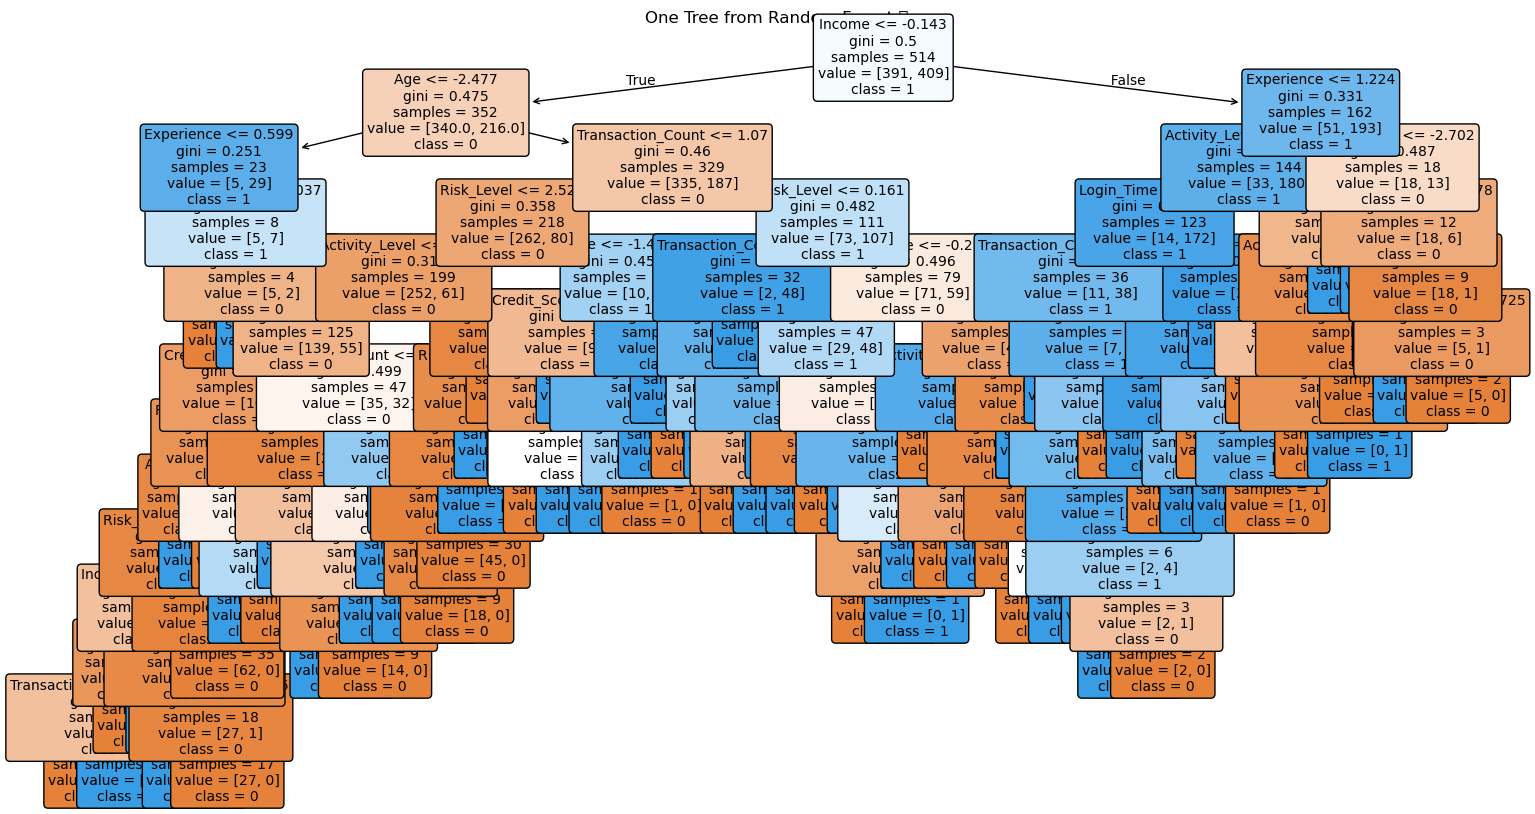

In [26]:
# Random Forest Model

rf = RandomForestClassifier(n_estimators=100)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

print("\n--- Random Forest ---")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))

# Plot
# Get one tree from Random Forest
tree = rf.estimators_[0]

# Plot that tree
plt.figure(figsize=(18,10))
plot_tree(
    tree,
    feature_names=X.columns,
    class_names=[str(cls) for cls in sorted(y.unique())],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("One Tree from Random Forest 🌳")
plt.show()

/opt/conda/envs/anaconda-2025.12-py312/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 127795 (\N{DECIDUOUS TREE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


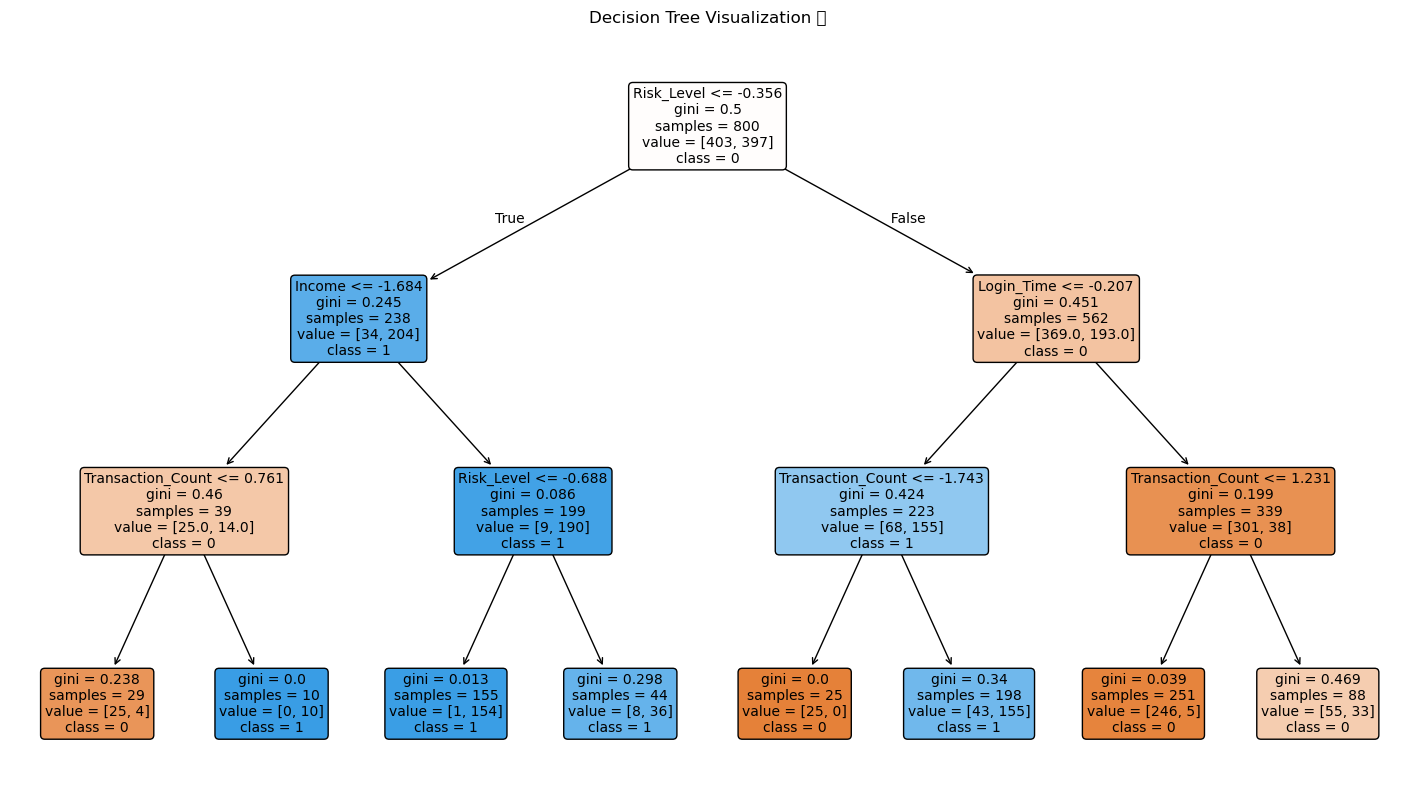

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
# Features & target
X = df.iloc[:, :-1]
y = df.iloc[:, -1]

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train model
dt = DecisionTreeClassifier(max_depth=3, random_state=42)
dt.fit(X_train, y_train)

# Plot tree
plt.figure(figsize=(18,10))
plot_tree(
    dt,
    feature_names=X.columns,
    class_names=[str(cls) for cls in sorted(y.unique())],  # cleaner labels
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Decision Tree Visualization 🌳")
plt.show()